# Analisis Penyebab Skor per Metrik — bart_warmup (method4)

Lanjutan dari analisis per-domain/panjang. Fokus di sini bukan *config mana yang menang* (sudah dipilih:
**bart_warmup**), melainkan **mengapa** sebuah dialog mendapat skor baik/buruk pada metrik tertentu.

Isi:
1. Profil tiap metrik & identifikasi dialog 'jeblok' per metrik (kuartil bawah metrik itu sendiri).
2. Apa yang membedakan dialog jeblok dari yang normal — fitur dialog (panjang, turn, #domain, #angka)
   dibandingkan dengan uji Mann-Whitney.
3. Interaksi **domain × panjang**: pivot, heatmap, uji efek panjang per domain.
4. Korelasi fitur → skor: fitur mana paling memprediksi tiap metrik.
5. Cek manual terarah per metrik (dialog + prediksi + referensi).

> Memakai `read_result`, `detect_domains`, `n_words` dari notebook analisis Anda. Jalankan sel-sel
> definisi itu lebih dulu, atau salin ke sini bila menjalankan mandiri.

## 0. Setup & load bart_warmup

Bila notebook ini dijalankan mandiri (tanpa sel-sel sebelumnya), sel berikut menyertakan ulang loader &
deteksi domain/panjang seperlunya. Bila `read_result` sudah ada di kernel, bagian itu otomatis dilewati.

In [1]:
import json, re, warnings
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import mannwhitneyu, kruskal, spearmanr
warnings.filterwarnings("ignore")
plt.rcParams["axes.grid"] = True; plt.rcParams["grid.alpha"] = 0.3

METHOD, CONFIG = "method4", "bart_warmup"
DIALOG_PATH = "data/all_dialogue_test_500.json"
N_LEN_BINS = 3

# --- fallback loader bila read_result belum ada di kernel ---
if "read_result" not in globals():
    def load_json(path):
        p = Path(path)
        if not p.is_file(): raise FileNotFoundError(p)
        with open(p, "r", encoding="utf-8") as f: return json.load(f)
    def read_result(method_num, path):
        base = Path(f"{method_num}_outputs") / path
        gen = load_json(base / "generated.json")
        generated = {k: [d[k] for d in gen] for k in gen[0]}
        uni = load_json(base / "unieval.json")
        unieval = {m: [it.get(m, 0) for it in uni] for m in ["coherence","relevance","fluency","consistency"]}
        align = {"align_score": load_json(base / "alignscore.json")}
        return pd.DataFrame({**unieval, **align, **generated})

if "detect_domains" not in globals():
    DOMAIN_KEYWORDS = {
        "hotel":      ["hotel","guesthouse","guest house","stay","room","lodge","star"],
        "restaurant": ["restaurant","eat","food","dine","dinner","lunch","cuisine","table"],
        "taxi":       ["taxi","cab","pick me up","pickup"],
        "train":      ["train","departure","arrive by","leave after","trainid"],
        "attraction": ["attraction","museum","park","college","gallery","nightclub","theatre"],
    }
    def detect_domains(text):
        t = str(text).lower()
        return [d for d,kws in DOMAIN_KEYWORDS.items() if any(k in t for k in kws)]
if "n_words" not in globals():
    def n_words(text): return len(re.findall(r"\w+", str(text)))

res = read_result(METHOD, CONFIG).reset_index(drop=True)
print("Config:", METHOD, CONFIG, "| kolom:", list(res.columns), "| baris:", len(res))

KNOWN = ["coherence","relevance","fluency","consistency","alignscore","align_score"]
metric_cols = [c for c in res.columns if pd.api.types.is_numeric_dtype(res[c]) and any(k in c.lower() for k in KNOWN)]
print("Metrik:", metric_cols)

Config: method4 bart_warmup | kolom: ['coherence', 'relevance', 'fluency', 'consistency', 'align_score', 'prompt', 'prediction', 'reference'] | baris: 499
Metrik: ['coherence', 'relevance', 'fluency', 'consistency', 'align_score']


## 1. Fitur dialog & bin panjang

Selain panjang & domain, kita tambahkan fitur sederhana yang masuk akal memengaruhi skor: jumlah turn
(perkiraan dari penanda giliran), jumlah domain yang disentuh, dan kepadatan entitas (angka, kode pos,
jam) — karena dialog MultiWOZ banyak memuat referensi/nomor yang rawan salah pada faktualitas.

In [2]:
dlg = pd.read_json(DIALOG_PATH)
col = dlg.columns[0]
texts = dlg[col].astype(str).reset_index(drop=True)
assert len(texts) == len(res), f"dialog {len(texts)} != hasil {len(res)}"

def n_turns(t):
    t = str(t)
    # perkiraan turn dari penanda umum; fallback ke baris
    m = len(re.findall(r"(?i)\b(user|system|usr|sys|assistant)\s*:", t))
    return m if m > 0 else (t.count("\n") + 1)
def n_numbers(t):   return len(re.findall(r"\d+", str(t)))
def n_postcode(t):  return len(re.findall(r"\b[A-Z]{1,2}\d{1,2}\s?\d?[A-Z]{0,2}\b", str(t)))
def n_times(t):     return len(re.findall(r"\b\d{1,2}[:.]\d{2}\b", str(t)))

res["_dialogue"] = texts.values
res["_domains"]  = texts.apply(detect_domains).values
res["_nwords"]   = texts.apply(n_words).values
res["_nturns"]   = texts.apply(n_turns).values
res["_ndomains"] = res["_domains"].apply(len).values
res["_nnums"]    = texts.apply(n_numbers).values
res["_npost"]    = texts.apply(n_postcode).values
res["_ntimes"]   = texts.apply(n_times).values
res["_numdens"]  = (res["_nnums"] / res["_nwords"].clip(lower=1)).round(4)

FEATURES = ["_nwords","_nturns","_ndomains","_nnums","_npost","_ntimes","_numdens"]

# bin panjang via kuantil
qs = [i/N_LEN_BINS for i in range(1, N_LEN_BINS)]
edges = res["_nwords"].quantile(qs).tolist()
labels = ["short","medium","long"] if N_LEN_BINS==3 else [f"bin{i+1}" for i in range(N_LEN_BINS)]
def length_bin(w):
    for i,e in enumerate(edges):
        if w <= e: return labels[i]
    return labels[-1]
res["_lenbin"] = res["_nwords"].apply(length_bin)
print("Batas bin (kata):", [round(e) for e in edges], "|", res["_lenbin"].value_counts().to_dict())
print("Fitur:", FEATURES)
print(res[FEATURES].describe().round(2).to_string())

Batas bin (kata): [123, 220] | {'medium': 167, 'short': 166, 'long': 166}
Fitur: ['_nwords', '_nturns', '_ndomains', '_nnums', '_npost', '_ntimes', '_numdens']
       _nwords  _nturns  _ndomains  _nnums  _npost  _ntimes  _numdens
count   499.00   499.00     499.00  499.00  499.00   499.00    499.00
mean    178.40     6.25       2.18    7.71    0.06     1.49      0.04
std      86.82     2.64       1.12    6.04    0.25     1.99      0.02
min      33.00     2.00       0.00    0.00    0.00     0.00      0.00
25%     103.00     4.00       1.00    3.00    0.00     0.00      0.02
50%     166.00     6.00       2.00    6.00    0.00     1.00      0.04
75%     245.00     8.00       3.00   11.00    0.00     2.00      0.05
max     457.00    14.00       5.00   33.00    2.00    11.00      0.13


## 2. Profil tiap metrik & dialog 'jeblok' per metrik

Untuk tiap metrik, dialog 'jeblok' = berada di **kuartil bawah metrik itu sendiri** (ambang relatif, karena
skala tiap metrik beda — lihat fluency vs coherence). Kita lihat berapa banyak dialog jeblok per metrik dan
seberapa tumpang-tindih antar metrik (apakah dialog yang jeblok di coherence juga jeblok di relevance).

In [3]:
Q = 0.1  # kuartil bawah
low_thr = {m: res[m].quantile(Q) for m in metric_cols}
low_mask = pd.DataFrame({m: res[m] <= low_thr[m] for m in metric_cols})

print("Ambang kuartil bawah tiap metrik:")
for m in metric_cols: print(f"  {m:14s} q{int(Q*100)} = {low_thr[m]:.3f}")

print("\nJumlah dialog 'jeblok' per metrik:")
print(low_mask.sum().to_string())

# tumpang tindih: berapa metrik sekaligus jeblok per dialog
res["_n_low"] = low_mask.sum(axis=1)
print("\nDistribusi: di berapa metrik sebuah dialog jeblok sekaligus:")
print(res["_n_low"].value_counts().sort_index().to_string())

# matriks ko-okurensi (Jaccard) antar metrik
print("\nJaccard overlap dialog-jeblok antar metrik (1=selalu bersamaan):")
J = pd.DataFrame(index=metric_cols, columns=metric_cols, dtype=float)
for a in metric_cols:
    for b in metric_cols:
        ia, ib = set(low_mask.index[low_mask[a]]), set(low_mask.index[low_mask[b]])
        J.loc[a,b] = len(ia & ib) / len(ia | ib) if (ia | ib) else 0.0
print(J.round(2).to_string())
print("\nJaccard rendah -> tiap metrik jeblok pada dialog yang berbeda (kegagalan metrik-spesifik).")

Ambang kuartil bawah tiap metrik:
  coherence      q10 = 0.669
  relevance      q10 = 0.539
  fluency        q10 = 0.657
  consistency    q10 = 0.784
  align_score    q10 = 0.610

Jumlah dialog 'jeblok' per metrik:
coherence      50
relevance      50
fluency        50
consistency    50
align_score    50

Distribusi: di berapa metrik sebuah dialog jeblok sekaligus:
_n_low
0    357
1     76
2     36
3     19
4     10
5      1

Jaccard overlap dialog-jeblok antar metrik (1=selalu bersamaan):
             coherence  relevance  fluency  consistency  align_score
coherence         1.00       0.33     0.23         0.35         0.11
relevance         0.33       1.00     0.16         0.27         0.12
fluency           0.23       0.16     1.00         0.23         0.08
consistency       0.35       0.27     0.23         1.00         0.12
align_score       0.11       0.12     0.08         0.12         1.00

Jaccard rendah -> tiap metrik jeblok pada dialog yang berbeda (kegagalan metrik-spesifik).


## 3. Apa yang membedakan dialog 'jeblok' dari yang normal? (per metrik)

Untuk tiap metrik, bandingkan rata-rata fitur antara kelompok jeblok (kuartil bawah) vs sisanya, dan uji
Mann-Whitney. Ini menjawab langsung 'kenapa metrik X buruk di dialog tertentu' dalam istilah fitur dialog.

In [4]:
for m in metric_cols:
    lo = res[low_mask[m]]
    hi = res[~low_mask[m]]
    print("="*72); print(f"METRIK: {m}  (jeblok n={len(lo)}, normal n={len(hi)})"); print("="*72)
    rows = []
    for f in FEATURES:
        try: p = mannwhitneyu(lo[f], hi[f], alternative="two-sided").pvalue
        except ValueError: p = np.nan
        rows.append({"fitur": f, "jeblok_mean": round(lo[f].mean(),3),
                     "normal_mean": round(hi[f].mean(),3),
                     "selisih": round(lo[f].mean()-hi[f].mean(),3),
                     "p": p, "sig": "*" if (p is not None and p<0.05) else ""})
    tab = pd.DataFrame(rows).sort_values("p")
    print(tab.to_string(index=False))
    # domain mana yang over-represented di kelompok jeblok
    lo_dom = lo.explode("_domains")["_domains"].value_counts(normalize=True)
    all_dom = res.explode("_domains")["_domains"].value_counts(normalize=True)
    skew = (lo_dom - all_dom).dropna().sort_values(ascending=False)
    if len(skew):
        print("  Domain lebih sering di kelompok jeblok (share_jeblok - share_total):")
        print("   ", {k: round(v,3) for k,v in skew.head(3).items()})
    print()

METRIK: coherence  (jeblok n=50, normal n=449)
    fitur  jeblok_mean  normal_mean  selisih        p sig
  _nwords      202.060      175.768   26.292 0.056770    
  _ntimes        2.000        1.437    0.563 0.074849    
   _nnums        9.160        7.546    1.614 0.086692    
  _nturns        6.740        6.200    0.540 0.204744    
 _numdens        0.044        0.040    0.004 0.287822    
   _npost        0.040        0.067   -0.027 0.494130    
_ndomains        2.100        2.187   -0.087 0.681916    
  Domain lebih sering di kelompok jeblok (share_jeblok - share_total):
    {'train': 0.031, 'hotel': 0.013, 'attraction': 0.007}

METRIK: relevance  (jeblok n=50, normal n=449)
    fitur  jeblok_mean  normal_mean  selisih        p sig
  _nwords      195.680      176.479   19.201 0.063385    
  _nturns        6.620        6.214    0.406 0.191850    
   _nnums        8.540        7.615    0.925 0.443476    
 _numdens        0.041        0.041   -0.000 0.756025    
  _ntimes        1.600

## 4. Korelasi fitur → skor (Spearman)

Ringkasan menyeluruh: fitur dialog mana yang paling kuat (dan ke arah mana) berhubungan dengan tiap metrik.
ρ negatif pada `_nwords` = makin panjang makin rendah skornya.

Spearman ρ (fitur × metrik):
           coherence  relevance  fluency  consistency  align_score
_nwords       -0.167     -0.218   -0.299       -0.154       -0.154
_nturns       -0.142     -0.187   -0.287       -0.131       -0.132
_ndomains     -0.049     -0.095   -0.218       -0.081       -0.071
_nnums        -0.106     -0.159   -0.241       -0.124       -0.039
_npost         0.040      0.133    0.018        0.046       -0.143
_ntimes       -0.094     -0.120   -0.182       -0.106        0.031
_numdens      -0.031     -0.058   -0.113       -0.068        0.073


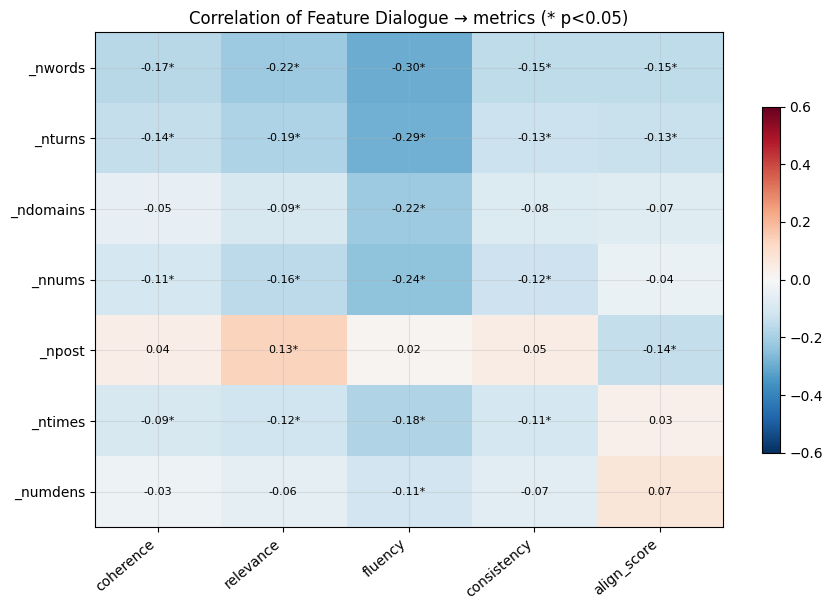

In [15]:
corr = pd.DataFrame(index=FEATURES, columns=metric_cols, dtype=float)
pmat = pd.DataFrame(index=FEATURES, columns=metric_cols, dtype=float)
for f in FEATURES:
    for m in metric_cols:
        rho, p = spearmanr(res[f], res[m])
        corr.loc[f,m] = rho; pmat.loc[f,m] = p
print("Spearman ρ (fitur × metrik):")
print(corr.astype(float).round(3).to_string())

fig, ax = plt.subplots(figsize=(1.4*len(metric_cols)+2, 0.6*len(FEATURES)+2))
im = ax.imshow(corr.astype(float).values, cmap="RdBu_r", vmin=-0.6, vmax=0.6, aspect="auto")
ax.set_xticks(range(len(metric_cols))); ax.set_xticklabels(metric_cols, rotation=40, ha="right")
ax.set_yticks(range(len(FEATURES))); ax.set_yticklabels(FEATURES)
for i in range(len(FEATURES)):
    for j in range(len(metric_cols)):
        v = corr.astype(float).values[i,j]
        star = "*" if pmat.astype(float).values[i,j] < 0.05 else ""
        ax.text(j, i, f"{v:.2f}{star}", ha="center", va="center", fontsize=8)
ax.set_title("Correlation of Feature Dialogue → metrics (* p<0.05)"); fig.colorbar(im, shrink=0.7)
plt.tight_layout(); plt.show()

## 5. Interaksi Domain × Panjang

Apakah efek panjang sama di semua domain, atau ada domain yang lebih 'tahan' terhadap dialog panjang?
Pivot (domain × bin panjang) per metrik + uji efek panjang di dalam tiap domain.

coherence  — mean per domain × panjang
_lenbin     short  medium   long
_domains                        
attraction  0.894   0.887  0.859
hotel       0.856   0.898  0.863
restaurant  0.902   0.882  0.858
taxi        0.943   0.885  0.891
train       0.885   0.886  0.848
  Δ(long-short) per domain (paling turun di atas): {'taxi': -0.052, 'restaurant': -0.044, 'train': -0.037, 'attraction': -0.035, 'hotel': 0.007}

relevance  — mean per domain × panjang
_lenbin     short  medium   long
_domains                        
attraction  0.916   0.875  0.827
hotel       0.834   0.860  0.801
restaurant  0.882   0.846  0.813
taxi        0.936   0.796  0.844
train       0.884   0.882  0.799
  Δ(long-short) per domain (paling turun di atas): {'taxi': -0.091, 'attraction': -0.089, 'train': -0.086, 'restaurant': -0.069, 'hotel': -0.033}

fluency  — mean per domain × panjang
_lenbin     short  medium   long
_domains                        
attraction  0.856   0.819  0.784
hotel       0.862   0.817  0.79

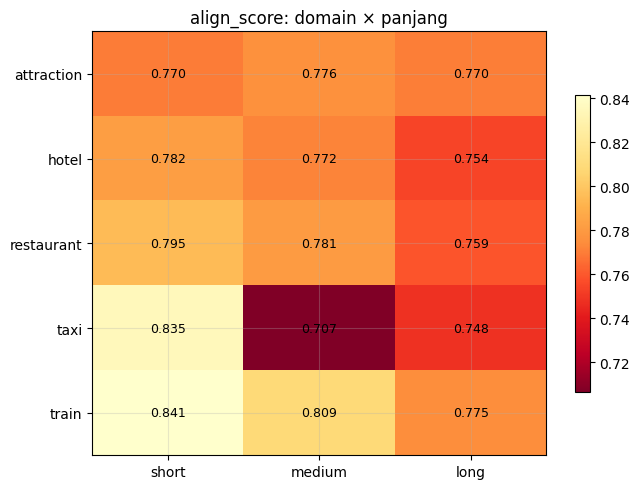

In [6]:
dom_rows = res.explode("_domains").dropna(subset=["_domains"])
order = [l for l in ["short","medium","long"] if l in res["_lenbin"].unique()]

for m in metric_cols:
    piv = dom_rows.pivot_table(index="_domains", columns="_lenbin", values=m, aggfunc="mean").reindex(columns=order)
    print("="*60); print(f"{m}  — mean per domain × panjang"); print("="*60)
    print(piv.round(3).to_string())
    # efek panjang = long - short per domain
    if "short" in piv.columns and "long" in piv.columns:
        drop = (piv["long"] - piv["short"]).sort_values()
        print("  Δ(long-short) per domain (paling turun di atas):", {k: round(v,3) for k,v in drop.items()})
    print()

# heatmap untuk satu metrik fokus (align_score bila ada, else metrik pertama)
focus = next((m for m in metric_cols if "align" in m.lower()), metric_cols[0])
piv = dom_rows.pivot_table(index="_domains", columns="_lenbin", values=focus, aggfunc="mean").reindex(columns=order)
fig, ax = plt.subplots(figsize=(1.6*len(order)+2, 0.6*len(piv)+2))
im = ax.imshow(piv.values, cmap="YlOrRd_r", aspect="auto")
ax.set_xticks(range(len(piv.columns))); ax.set_xticklabels(piv.columns)
ax.set_yticks(range(len(piv.index))); ax.set_yticklabels(piv.index)
for i in range(len(piv.index)):
    for j in range(len(piv.columns)):
        ax.text(j, i, f"{piv.values[i,j]:.3f}", ha="center", va="center", fontsize=9)
ax.set_title(f"{focus}: domain × panjang"); fig.colorbar(im, shrink=0.7)
plt.tight_layout(); plt.show()

### 5b. Uji formal interaksi domain × panjang

Untuk tiap metrik: apakah panjang berpengaruh **di dalam** tiap domain (Kruskal per domain)? Jika sebuah
domain tidak signifikan padahal lainnya signifikan, domain itu relatif tahan terhadap panjang.

In [7]:
for m in metric_cols:
    print("="*60); print(f"{m}: efek panjang DI DALAM tiap domain"); print("="*60)
    for d in sorted(dom_rows["_domains"].unique()):
        sub = dom_rows[dom_rows["_domains"]==d]
        groups = [sub[sub["_lenbin"]==b][m].dropna() for b in order]
        groups = [g for g in groups if len(g)>1]
        if len(groups) >= 2:
            H, p = kruskal(*groups)
            sig = "**SIG**" if p<0.05 else "ns"
            print(f"  {d:11s} Kruskal p={p:.3g} [{sig}]  (n={len(sub)})")
    print()

coherence: efek panjang DI DALAM tiap domain
  attraction  Kruskal p=0.0324 [**SIG**]  (n=230)
  hotel       Kruskal p=0.0568 [ns]  (n=214)
  restaurant  Kruskal p=0.00352 [**SIG**]  (n=400)
  taxi        Kruskal p=0.068 [ns]  (n=90)
  train       Kruskal p=0.0182 [**SIG**]  (n=153)

relevance: efek panjang DI DALAM tiap domain
  attraction  Kruskal p=0.0157 [**SIG**]  (n=230)
  hotel       Kruskal p=0.366 [ns]  (n=214)
  restaurant  Kruskal p=0.000666 [**SIG**]  (n=400)
  taxi        Kruskal p=0.0611 [ns]  (n=90)
  train       Kruskal p=0.0538 [ns]  (n=153)

fluency: efek panjang DI DALAM tiap domain
  attraction  Kruskal p=0.00332 [**SIG**]  (n=230)
  hotel       Kruskal p=0.00572 [**SIG**]  (n=214)
  restaurant  Kruskal p=3.59e-09 [**SIG**]  (n=400)
  taxi        Kruskal p=0.0363 [**SIG**]  (n=90)
  train       Kruskal p=0.0448 [**SIG**]  (n=153)

consistency: efek panjang DI DALAM tiap domain
  attraction  Kruskal p=0.108 [ns]  (n=230)
  hotel       Kruskal p=0.234 [ns]  (n=214)
  

## 6. Cek manual terarah — per metrik

Untuk tiap metrik, cetak beberapa dialog dengan skor metrik **terendah** beserta prediksi & referensi, agar
Anda membaca penyebab sesungguhnya (mis. salah nomor referensi → align rendah; kalimat menggantung → fluency
rendah). Ini bukti kualitatif untuk paper.

In [11]:
import textwrap
PRED_COL = next((c for c in res.columns if c.lower() in ["prediction","pred","generated","hypothesis","output"]), None)
REF_COL  = next((c for c in res.columns if c.lower() in ["reference","ref","target","gold","label"]), None)
print("PRED_COL:", PRED_COL, "| REF_COL:", REF_COL)
K = 3

def show(idx, judul):
    print("\n" + "="*78); print(judul); print("="*78)
    for i in idx:
        r = res.loc[i]
        feat = f"len={int(r['_nwords'])} turns={int(r['_nturns'])} doms={r['_domains']} nums={int(r['_nnums'])}"
        print(f"\n[row {i}] {feat}")
        print("  skor:", " ".join(f"{m}={r[m]:.3f}" for m in metric_cols))
        print("  DIALOG:", textwrap.shorten(str(r["_dialogue"]).replace("\n"," ⏎ "), 1000))
        if REF_COL:  print("  REF   :", textwrap.shorten(str(r[REF_COL]), 400))
        if PRED_COL: print("  PRED  :", textwrap.shorten(str(r[PRED_COL]), 400))

for m in metric_cols:
    show(res.nsmallest(K, m).index, f"{m.upper()} TERENDAH — kenapa metrik ini jeblok di sini?")

PRED_COL: prediction | REF_COL: reference

COHERENCE TERENDAH — kenapa metrik ini jeblok di sini?

[row 192] len=119 turns=5 doms=['restaurant'] nums=0
  skor: coherence=0.047 relevance=0.114 fluency=0.709 consistency=0.759 align_score=0.585
  DIALOG: user: I'm looking for an expensive restaurant in the center of town. ⏎ agent: Certainly. Some choices that fit your criteria are Bedouin, Kymmoy, and Fitzbillies Restaurant. ⏎ user: What are the different food types of these restaurants? ⏎ agent: In the same order: African, Asian Oriental, British. Do any of these fancy you? ⏎ user: Not actually. I won't be needing anything else at this time. thank you. Good bye. ⏎ agent: You don't need any other information? ⏎ user: That's all I need from you today. Thanks. ⏎ agent: Alright. I hope you have a wonderful day! ⏎ user: Thank you for your help ⏎ agent: You're quite welcome! Thanks for contacting the Cambridge TownInfo Centre and have a great day!
  REF   : User Profile: A user seeking an expe

## 7. Ekspor

In [9]:
corr.astype(float).round(3).to_csv("warmup_feature_metric_corr.csv")
out_cols = ["_nwords","_nturns","_ndomains","_nnums","_npost","_ntimes","_lenbin","_n_low"] + metric_cols
res[out_cols + ([PRED_COL] if PRED_COL else []) + ([REF_COL] if REF_COL else [])].to_csv("warmup_per_dialog_features.csv", index_label="row")
print("Disimpan: warmup_feature_metric_corr.csv, warmup_per_dialog_features.csv")
print("""
CARA MENYIMPULKAN:
- Sel 3 (discriminative): jika kelompok 'jeblok' suatu metrik konsisten lebih panjang / lebih banyak angka,
  itu penjelasan fitur untuk kegagalan metrik tsb.
- Sel 4 (korelasi): ringkas arah & kekuatan; biasanya _nwords berkorelasi negatif kuat dgn coherence/relevance.
- Sel 5: cari domain yang Δ(long-short) paling kecil = paling tahan panjang; dan yang paling negatif = paling rapuh.
- Sel 6: baca kasus nyata untuk menamai jenis kesalahan (faktual/numerik vs linguistik). Gabungkan temuan
  kuantitatif (sel 3-5) dengan contoh kualitatif (sel 6) untuk argumen 'kenapa skor baik/buruk' di paper.""")

Disimpan: warmup_feature_metric_corr.csv, warmup_per_dialog_features.csv

CARA MENYIMPULKAN:
- Sel 3 (discriminative): jika kelompok 'jeblok' suatu metrik konsisten lebih panjang / lebih banyak angka,
  itu penjelasan fitur untuk kegagalan metrik tsb.
- Sel 4 (korelasi): ringkas arah & kekuatan; biasanya _nwords berkorelasi negatif kuat dgn coherence/relevance.
- Sel 5: cari domain yang Δ(long-short) paling kecil = paling tahan panjang; dan yang paling negatif = paling rapuh.
- Sel 6: baca kasus nyata untuk menamai jenis kesalahan (faktual/numerik vs linguistik). Gabungkan temuan
  kuantitatif (sel 3-5) dengan contoh kualitatif (sel 6) untuk argumen 'kenapa skor baik/buruk' di paper.


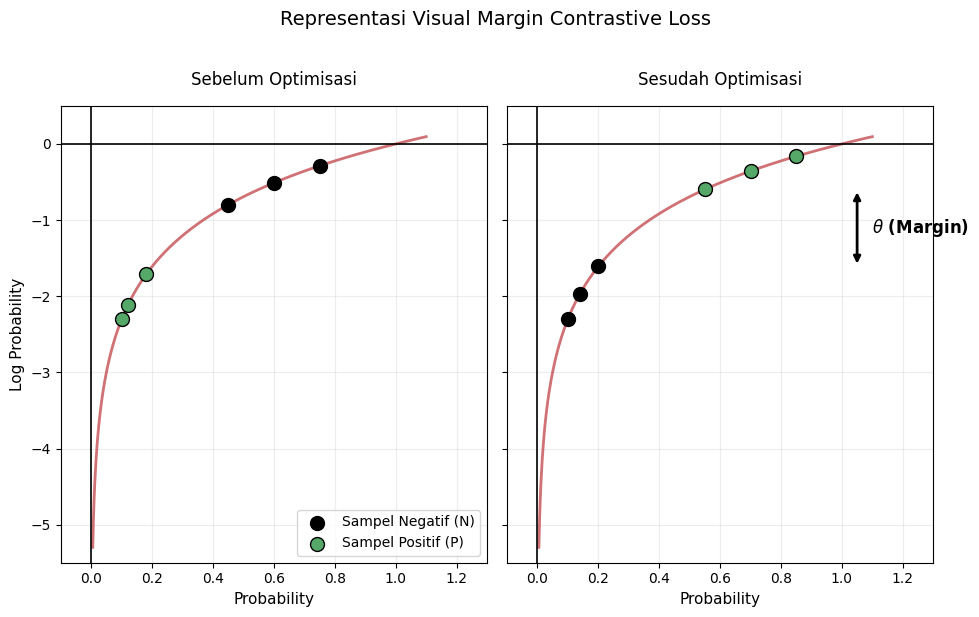

In [12]:
import numpy as np
import matplotlib.pyplot as plt

# Konfigurasi parameter kurva
x = np.linspace(0.005, 1.1, 500)
y = np.log(x)

# Inisialisasi figur dengan 2 subplot (Before & After)
fig, axes = plt.subplots(1, 2, figsize=(10, 6), sharey=True)
fig.patch.set_facecolor('white')

# ==========================================
# PLOT 1: SEBELUM OPTIMISASI (BEFORE)
# ==========================================
ax1 = axes[0]
ax1.plot(x, y, color="#C44E52", lw=2, alpha=0.8) # Kurva merah

# Posisi titik sebelum dilatih (Kondisi buruk: Negatif > Positif)
neg_x_before = np.array([0.45, 0.60, 0.75])
pos_x_before = np.array([0.10, 0.12, 0.18])

# Plot scatter
ax1.scatter(neg_x_before, np.log(neg_x_before), color='black', s=100, zorder=5, label='Sampel Negatif (N)')
ax1.scatter(pos_x_before, np.log(pos_x_before), color='#55A868', s=100, edgecolors='black', zorder=5, label='Sampel Positif (P)')

ax1.set_title("Sebelum Optimisasi", fontsize=12, pad=15)
ax1.set_ylabel("Log Probability", fontsize=11)
ax1.legend(loc='lower right', fontsize=10)

# ==========================================
# PLOT 2: SESUDAH OPTIMISASI (AFTER)
# ==========================================
ax2 = axes[1]
ax2.plot(x, y, color="#C44E52", lw=2, alpha=0.8) # Kurva merah

# Posisi titik sesudah dilatih (Kondisi ideal: Positif > Negatif + Margin)
pos_x_after = np.array([0.55, 0.70, 0.85])
neg_x_after = np.array([0.10, 0.14, 0.20])

# Plot scatter
ax2.scatter(neg_x_after, np.log(neg_x_after), color='black', s=100, zorder=5)
ax2.scatter(pos_x_after, np.log(pos_x_after), color='#55A868', s=100, edgecolors='black', zorder=5)

# Kalkulasi batas margin
min_pos_y = np.min(np.log(pos_x_after))
max_neg_y = np.max(np.log(neg_x_after))

# Menggambar anotasi margin (Theta)
ax2.annotate('', xy=(1.05, max_neg_y), xytext=(1.05, min_pos_y),
             arrowprops=dict(arrowstyle='<|-|>', color='black', lw=2))
ax2.text(1.10, (min_pos_y + max_neg_y)/2, r'$\theta$ (Margin)', 
         verticalalignment='center', fontsize=12, fontweight='bold')

ax2.set_title("Sesudah Optimisasi", fontsize=12, pad=15)

# ==========================================
# KONFIGURASI ESTETIKA GLOBAL
# ==========================================
for ax in axes:
    ax.set_xlim(-0.1, 1.3)
    ax.set_ylim(-5.5, 0.5)
    
    # Garis sumbu X dan Y pada titik 0
    ax.axhline(0, color='black', lw=1.2)
    ax.axvline(0, color='black', lw=1.2)
    
    # Grid penolong
    ax.grid(True, linestyle='-', alpha=0.4, color='#D3D3D3')
    ax.set_xlabel("Probability", fontsize=11)

plt.suptitle("Representasi Visual Margin Contrastive Loss", fontsize=14, y=1.02)
plt.tight_layout()
plt.savefig("margin_contrast_visualization.png", dpi=300, bbox_inches="tight")
plt.show()

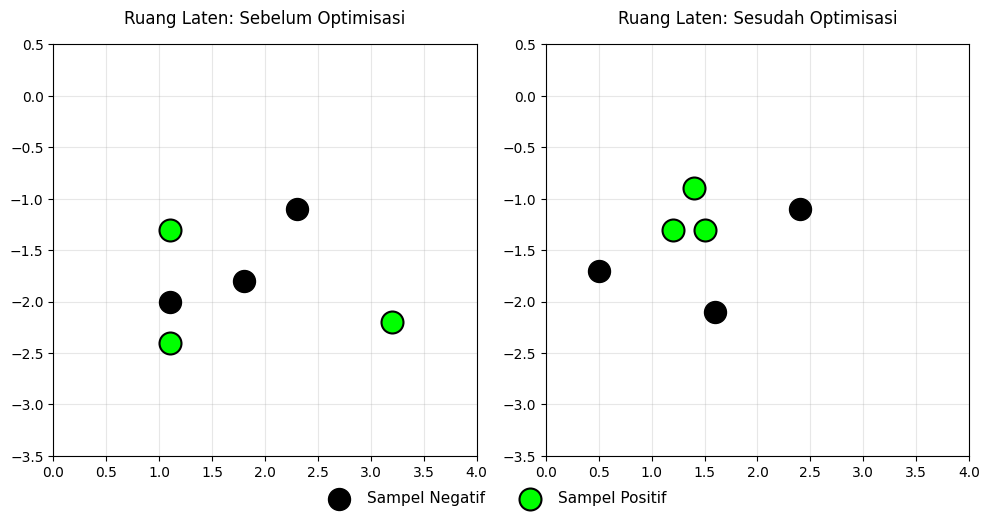

In [14]:
import matplotlib.pyplot as plt

# Inisialisasi figur dengan 2 subplot berjajar (Kiri: Sebelum, Kanan: Sesudah)
# Format 1x2 lebih efisien untuk ruang halaman dokumen akademik
fig, axes = plt.subplots(1, 2, figsize=(10, 5))
fig.patch.set_facecolor('white')

# ==========================================
# DATA REPRESENTASI RUANG LATEN 2D
# ==========================================
# 1. Sebelum Optimisasi (Tersebar acak, tumpang tindih)
pos_x_before = [1.1, 1.1, 3.2]
pos_y_before = [-1.3, -2.4, -2.2]
neg_x_before = [1.1, 1.8, 2.3]
neg_y_before = [-2.0, -1.8, -1.1]

# 2. Sesudah Optimisasi (Positif mengelompok/Alignment, Negatif menjauh/Uniformity)
pos_x_after = [1.4, 1.2, 1.5]
pos_y_after = [-0.9, -1.3, -1.3]
neg_x_after = [0.5, 1.6, 2.4]
neg_y_after = [-1.7, -2.1, -1.1]

# ==========================================
# PLOT 1: SEBELUM OPTIMISASI
# ==========================================
axes[0].scatter(neg_x_before, neg_y_before, color='black', s=250, label='Sampel Negatif', zorder=3)
axes[0].scatter(pos_x_before, pos_y_before, color='#00FF00', s=250, edgecolors='black', linewidths=1.5, label='Sampel Positif', zorder=3)
axes[0].set_title("Ruang Laten: Sebelum Optimisasi", fontsize=12, pad=15)

# ==========================================
# PLOT 2: SESUDAH OPTIMISASI
# ==========================================
axes[1].scatter(neg_x_after, neg_y_after, color='black', s=250, zorder=3)
axes[1].scatter(pos_x_after, pos_y_after, color='#00FF00', s=250, edgecolors='black', linewidths=1.5, zorder=3)
axes[1].set_title("Ruang Laten: Sesudah Optimisasi", fontsize=12, pad=15)

# ==========================================
# PENGHAPUSAN SUMBU KARTESIAN & ESTETIKA
# ==========================================
for ax in axes:
    # Mengunci batas skala agar pergerakan titik terlihat proporsional
    ax.set_xlim(0, 4)
    ax.set_ylim(-3.5, 0.5)
    
    # Menghapus sumbu X dan Y, angka, serta bingkai secara total
    # ax.axis('off')

# Menambahkan legenda global di bagian bawah
fig.legend(['Sampel Negatif', 'Sampel Positif'], loc='lower center', ncol=2, bbox_to_anchor=(0.5, -0.05), fontsize=11, frameon=False)

plt.tight_layout()
plt.savefig("latent_space_no_axes.png", dpi=300, bbox_inches="tight")
plt.show()